# PCB Defect Detection — End-to-End Object Detection Pipeline

**Task:** Detect and classify manufacturing defects on printed circuit boards (PCBs)  
**Dataset:** [PCB Defect Dataset (COCO format)](https://universe.roboflow.com/hubei-university-of-technology-rmbpi/pcb-ecjga)  
**Models benchmarked:** Faster R-CNN · RetinaNet · FCOS  
**Final model:** FCOS ResNet-50 FPN (best speed–accuracy trade-off)

---


## 1 · Environment Setup


In [1]:
# Mount Google Drive to access the dataset archive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
# Install libraries not bundled with the Colab base image
!pip install -q albumentations torchmetrics pycocotools

In [ ]:
# ── Standard-library & third-party imports used throughout the notebook ──────
import json
import math
import random
import shutil
import time
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.optim as optim
import torchvision
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader, Dataset
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.fcos import FCOSHead
from torchvision.models.detection.retinanet import RetinaNetHead
from tqdm import tqdm

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ── Device ────────────────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── Global constants ──────────────────────────────────────────────────────────
IMG_SIZE        = 640          # Input resolution for all models
BATCH_SIZE      = 8            # Adjust to 4 / 16 based on available VRAM
NUM_WORKERS     = 2
IMAGENET_MEAN   = [0.485, 0.456, 0.406]
IMAGENET_STD    = [0.229, 0.224, 0.225]
MAX_GRAD_NORM   = 1.0          # Gradient-clipping threshold
CONF_THRESHOLD  = 0.40         # Inference score threshold for visualisation

# Class names (index 0 is background — never predicted)
CLASS_NAMES = {
    1: "spurious_copper",
    2: "missing_hole",
    3: "mouse_bite",
    4: "open_circuit",
    5: "pinhole",
    6: "scratch",
    7: "short",
    8: "spur",
}

print(f" Device        : {DEVICE}")
print(f" Torch version : {torch.__version__}")
print(f" Seed          : {SEED}")


 Device        : cuda
 Torch version : 2.11.0+cu130
 Seed          : 42


## 2 · Data Preparation

The raw dataset ships as a single zip containing two COCO-format splits
(`train` / `valid`).  We re-merge them, shuffle deterministically, and
partition into **70 % train · 15 % val · 15 % test** before any model sees
the data.

An ID offset of 10 000 is added to every `valid` image / annotation ID to
prevent collisions when the two splits are merged into the same list.


In [6]:
!unzip -q "/content/drive/MyDrive/PCB.v1-pcb-defect-v1.coco.zip" -d "/content/PCB_Dataset"
print("Dataset archive extracted.")


Dataset archive extracted.


In [7]:
def build_split(
    src_dir: str | Path = "PCB_Dataset",
    dst_dir: str | Path = "PCB_Dataset_Split",
    ratios: tuple[float, float, float] = (0.70, 0.15, 0.15),
    seed: int = SEED,
) -> None:
    """
    Merge the original train/valid COCO splits, re-shuffle, and write
    train / val / test partitions with physical image copies.

    Args:
        src_dir: Directory produced by unzipping the raw archive.
        dst_dir: Output root for the new three-way split.
        ratios:  (train, val, test) fractions — must sum to 1.
        seed:    Random seed for reproducible shuffling.
    """
    assert abs(sum(ratios) - 1.0) < 1e-6, "ratios must sum to 1"

    src = Path(src_dir)
    dst = Path(dst_dir)
    imgs, anns = [], []
    categories = []

    for i, split in enumerate(["train", "valid"]):
        with open(src / split / "_annotations.coco.json") as f:
            data = json.load(f)

        categories = data["categories"]
        # Offset valid IDs to avoid collisions with train IDs
        offset = 10_000 if split == "valid" else 0

        for img in data["images"]:
            img["id"] += offset
            img["_src"] = src / split / img["file_name"]   # temp key
            imgs.append(img)

        for ann in data["annotations"]:
            ann["id"]       += offset
            ann["image_id"] += offset
            anns.append(ann)

    random.seed(seed)
    random.shuffle(imgs)

    n = len(imgs)
    t1 = int(n * ratios[0])
    t2 = int(n * (ratios[0] + ratios[1]))
    split_map = {"train": imgs[:t1], "val": imgs[t1:t2], "test": imgs[t2:]}

    for name, split_imgs in split_map.items():
        (dst / name / "images").mkdir(parents=True, exist_ok=True)

        for img in split_imgs:
            shutil.copy(img.pop("_src"), dst / name / "images" / img["file_name"])

        ids = {img["id"] for img in split_imgs}
        split_anns = [a for a in anns if a["image_id"] in ids]

        with open(dst / name / "_annotations.coco.json", "w") as f:
            json.dump(
                {"categories": categories, "images": split_imgs, "annotations": split_anns},
                f,
            )

        print(f" {name:5s} — {len(split_imgs):4d} images | {len(split_anns):5d} annotations")

    print(" Dataset split complete.")


build_split()


 train — 2607 images | 13758 annotations
 val   —  559 images |  3008 annotations
 test  —  559 images |  2991 annotations
 Dataset split complete.


## 3 · Dataset & DataLoaders

### 3.1 · PyTorch Dataset


In [8]:
class PCBCOCODataset(Dataset):
    """
    COCO-format dataset for PCB defect detection.

    Handles:
    - BGR → RGB conversion
    - Filtering of background annotations (category_id == 0)
    - COCO [x, y, w, h] → Pascal VOC [xmin, ymin, xmax, ymax] conversion
    - Degenerate box removal (< 2 × 2 px after augmentation)
    - Albumentations-compatible transform pipeline

    Args:
        root_dir:  Root directory with train / val / test subfolders.
        split:     Which subset to load.
        transform: Albumentations ``Compose`` pipeline (or None).
    """

    def __init__(self, root_dir: str, split: str = "train", transform=None):
        self.transform = transform
        self.img_dir   = Path(root_dir) / split / "images"
        json_path      = Path(root_dir) / split / "_annotations.coco.json"

        with open(json_path) as f:
            data = json.load(f)

        self.images     = {img["id"]: img for img in data["images"]}
        self.img_ids    = list(self.images.keys())
        self.categories = {cat["id"]: cat["name"] for cat in data["categories"]}

        # Build an O(1) lookup: image_id -> [annotation, ...]
        self.annotations: dict[int, list] = defaultdict(list)
        for ann in data["annotations"]:
            self.annotations[ann["image_id"]].append(ann)

    # ── protocol ─────────────────────────────────────────────────────────────

    def __len__(self) -> int:
        return len(self.img_ids)

    def __getitem__(self, idx: int):
        image_id = self.img_ids[idx]
        img_meta = self.images[image_id]

        # Load image (OpenCV reads BGR; convert to RGB for consistency)
        img_path = str(self.img_dir / img_meta["file_name"])
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Image not found: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Collect boxes & labels; skip background class (id == 0)
        bboxes, labels = [], []
        for ann in self.annotations[image_id]:
            if ann["category_id"] == 0:
                continue
            bboxes.append(ann["bbox"])
            labels.append(ann["category_id"])

        # Apply augmentation pipeline (if provided)
        if self.transform:
            aug    = self.transform(image=image, bboxes=bboxes, category_ids=labels)
            image  = aug["image"]
            bboxes = aug["bboxes"]
            labels = aug["category_ids"]
        else:
            # Fallback: HWC uint8 → CHW float in [0, 1]
            image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

        # COCO [x, y, w, h] → Pascal VOC [xmin, ymin, xmax, ymax]
        # Discard boxes that degenerate to < 2 × 2 px after augmentation
        pascal_boxes, clean_labels = [], []
        for (x, y, w, h), label in zip(bboxes, labels):
            xmin, ymin, xmax, ymax = x, y, x + w, y + h
            if (xmax > xmin + 1) and (ymax > ymin + 1):
                pascal_boxes.append([xmin, ymin, xmax, ymax])
                clean_labels.append(label)

        if pascal_boxes:
            boxes  = torch.tensor(pascal_boxes, dtype=torch.float32)
            labels = torch.tensor(clean_labels,  dtype=torch.int64)
        else:
            boxes  = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,),   dtype=torch.int64)

        target = {
            "boxes":    boxes,
            "labels":   labels,
            "image_id": torch.tensor([int(image_id)], dtype=torch.int64),
        }
        return image, target


### 3.2 · Augmentation Pipelines

**Training:** geometric flips and 90° rotations enforce rotation-invariance
— useful because PCBs can be oriented arbitrarily on the production line.
CLAHE improves contrast on over/under-exposed PCB images.  CoarseDropout
acts as a mild regulariser to reduce over-fitting on the small dataset.

**Val / Test:** deterministic resize + normalise only.  No stochastic
transforms must be applied at evaluation time.


In [9]:
train_transform = A.Compose(
    [
        A.Resize(height=IMG_SIZE, width=IMG_SIZE),

        # Geometric — production-line boards can arrive in any orientation
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),

        # Photometric — compensates for varying lighting conditions
        A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.3),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.4),

        # Regularisation — simulates partial occlusion / sensor noise
        A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.3),

        # ImageNet normalisation + CHW tensor conversion
        A.Normalize(mean=(0.0, 0.0, 0.0), std=(1.0, 1.0, 1.0), max_pixel_value=255.0),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(
        format="coco", min_visibility=0.3, label_fields=["category_ids"]
    ),
)

val_transform = A.Compose(
    [
        A.Resize(height=IMG_SIZE, width=IMG_SIZE),
        A.Normalize(mean=(0.0, 0.0, 0.0), std=(1.0, 1.0, 1.0), max_pixel_value=255.0),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(format="coco", label_fields=["category_ids"]),
)


/tmp/ipykernel_851/2812956278.py:15: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.3),


### 3.3 · DataLoaders


In [10]:
def collate_fn(batch):
    """
    Object-detection collate: images and targets stay as tuples.
    Standard torch.stack cannot be used because each image may contain
    a different number of bounding boxes.
    """
    return tuple(zip(*batch))


ROOT = "PCB_Dataset_Split"

train_dataset = PCBCOCODataset(ROOT, split="train", transform=train_transform)
val_dataset   = PCBCOCODataset(ROOT, split="val",   transform=val_transform)
test_dataset  = PCBCOCODataset(ROOT, split="test",  transform=val_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, collate_fn=collate_fn, pin_memory=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, collate_fn=collate_fn, pin_memory=True,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, collate_fn=collate_fn, pin_memory=True,
)

NUM_CLASSES = len(train_dataset.categories) + 1  # +1 for background

print(f" Train set     : {len(train_dataset):4d} images")
print(f" Val set       : {len(val_dataset):4d} images")
print(f" Test set      : {len(test_dataset):4d} images")
print(f" Defect classes: {len(train_dataset.categories)}  "
      f"({', '.join(train_dataset.categories.values())})")


 Train set     : 2607 images
 Val set       :  559 images
 Test set      :  559 images
 Defect classes: 9  (PCB, falsecopper, missinghole, mousebite, opencircuit, pinhole, scratch, shortcircuit, spur)


## 4 · Exploratory Data Analysis

Before training, it is worth verifying that annotations were parsed
correctly, understanding the class distribution, and confirming that the
augmentation pipeline does not corrupt boxes.


### 4.1 · Visualisation Utilities

These functions are defined once and reused throughout the notebook — in EDA,
training monitoring, and final inference.


In [27]:
# ─── colour palette — one deterministic colour per class ─────────────────────
_PALETTE = {
    class_id: tuple(int(c) for c in np.random.default_rng(class_id).integers(80, 230, 3))
    for class_id in CLASS_NAMES
}

# Ground-truth uses blue; predictions use green — consistent throughout
GT_COLOUR   = (220, 80,  80)   # BGR soft red  → rendered as blue in matplotlib (RGB)
PRED_COLOUR = (80,  200, 80)   # BGR soft green


def tensor_to_uint8(tensor: torch.Tensor) -> np.ndarray:
    """
    NumPy array in RGB colour space, ready for matplotlib.
    """
    img  = tensor.permute(1, 2, 0).cpu().numpy()
    img  = img.clip(0, 1)
    return (img * 255).astype(np.uint8)


def draw_boxes(
    image_rgb: np.ndarray,
    boxes: np.ndarray,
    labels: np.ndarray,
    scores: np.ndarray | None = None,
    class_names: dict = CLASS_NAMES,
    default_colour: tuple = GT_COLOUR,
    thickness: int = 2,
    font_scale: float = 0.45,
) -> np.ndarray:
    """
    Draw labelled bounding boxes on a copy of ``image_rgb``.

    Args:
        image_rgb:     HWC uint8 RGB image (will not be modified in-place).
        boxes:         (N, 4) array of [xmin, ymin, xmax, ymax] boxes.
        labels:        (N,)   array of integer class IDs.
        scores:        (N,)   confidence scores.  If None, label only.
        class_names:   Mapping from class ID to display name.
        default_colour: BGR fallback colour when palette lookup fails.
        thickness:     Box border thickness in pixels.
        font_scale:    OpenCV font scale.

    Returns:
        Annotated RGB image as a uint8 NumPy array.
    """
    canvas = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    for i, (box, label) in enumerate(zip(boxes, labels)):
        xmin, ymin, xmax, ymax = map(int, box)
        colour  = _PALETTE.get(int(label), default_colour)
        name    = class_names.get(int(label), f"cls_{label}")
        caption = f"{name} {scores[i]:.2f}" if scores is not None else name

        # Box
        cv2.rectangle(canvas, (xmin, ymin), (xmax, ymax), colour, thickness)

        # Label background + text
        (tw, th), _ = cv2.getTextSize(caption, cv2.FONT_HERSHEY_SIMPLEX, font_scale, 1)
        cv2.rectangle(
            canvas,
            (xmin, max(ymin - th - 6, 0)),
            (xmin + tw, max(ymin, th + 6)),
            colour, -1,
        )
        cv2.putText(
            canvas, caption,
            (xmin, max(ymin - 4, th + 2)),
            cv2.FONT_HERSHEY_SIMPLEX, font_scale,
            (255, 255, 255), 1, cv2.LINE_AA,
        )

    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


def show_grid(images_rgb: list[np.ndarray], titles: list[str], cols: int = 3) -> None:
    """Display a variable-length list of annotated images in a grid layout."""
    rows = math.ceil(len(images_rgb) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    axes = np.array(axes).flatten()

    for ax, img, title in zip(axes, images_rgb, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

    for ax in axes[len(images_rgb):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


### 4.2 · Ground-Truth Annotation Spot-Check


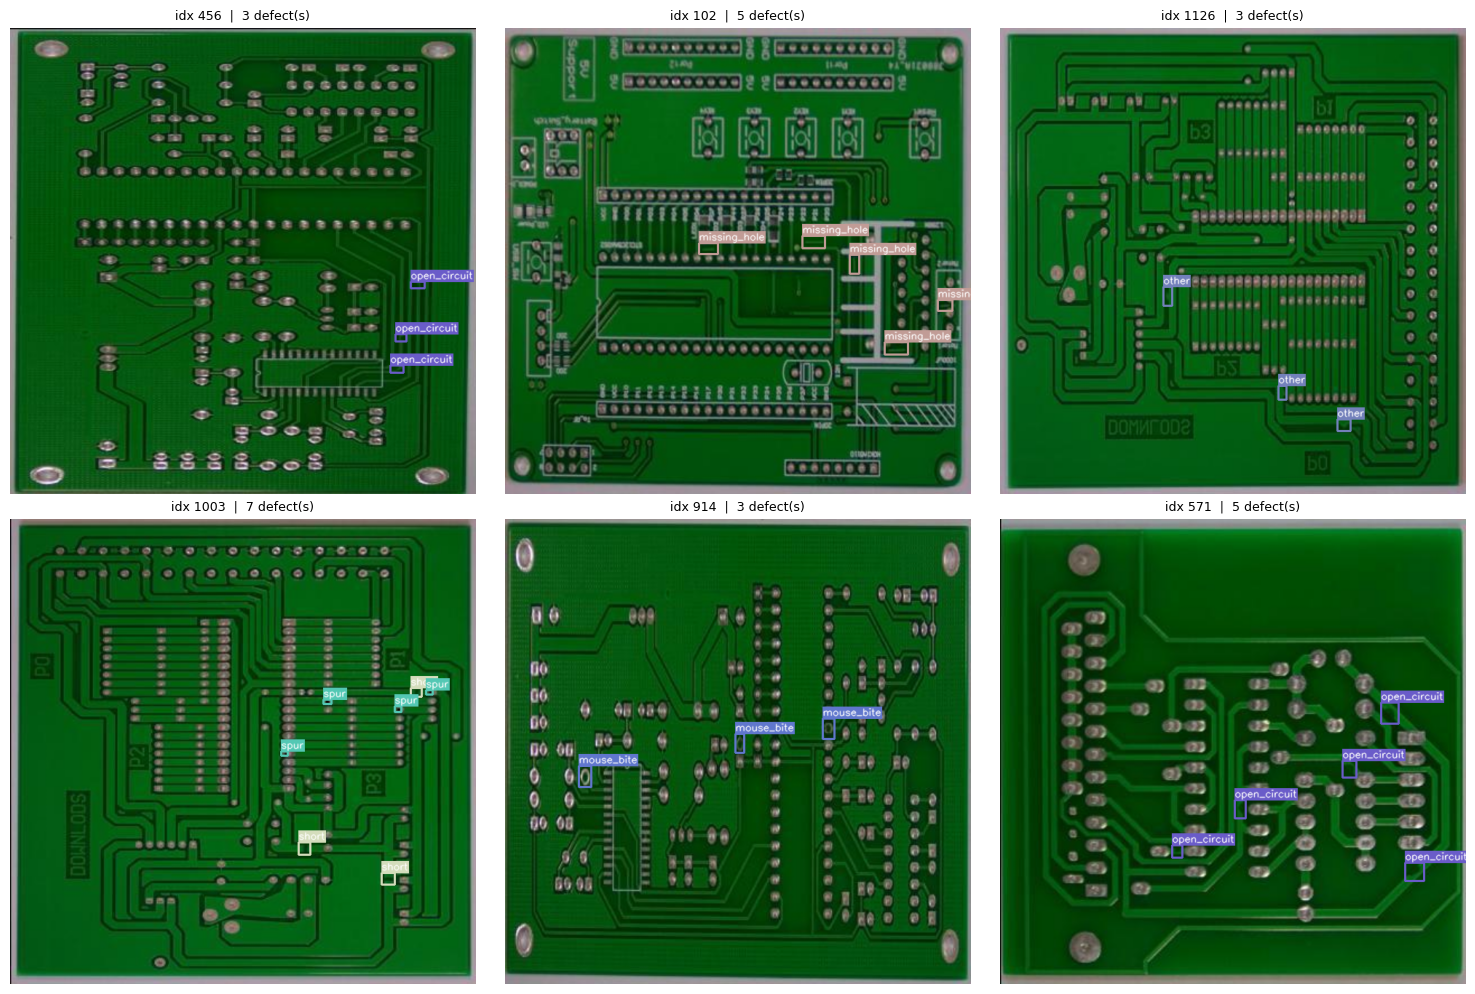

In [ ]:
def visualize_ground_truth(dataset: PCBCOCODataset, n: int = 6, seed: int = SEED) -> None:
    """
    Sample ``n`` images from ``dataset`` and display them with their
    ground-truth bounding boxes drawn on top.

    Useful for validating that the COCO parser and coordinate-conversion
    logic work correctly before any model is involved.
    """
    rng     = random.Random(seed)
    indices = rng.sample(range(len(dataset)), n)

    annotated, titles = [], []
    for idx in indices:
        image_tensor, target = dataset[idx]
        image_rgb = tensor_to_uint8(image_tensor)

        boxes  = target["boxes"].numpy()
        labels = target["labels"].numpy()

        annotated.append(draw_boxes(image_rgb, boxes, labels))
        titles.append(f"idx {idx}  |  {len(boxes)} defect(s)")

    show_grid(annotated, titles)


# Use the raw (no-transform) dataset so we see unmodified images first
_eda_dataset = PCBCOCODataset(ROOT, split="train", transform=val_transform)
visualize_ground_truth(_eda_dataset, n=6)


### 4.3 · Class Distribution


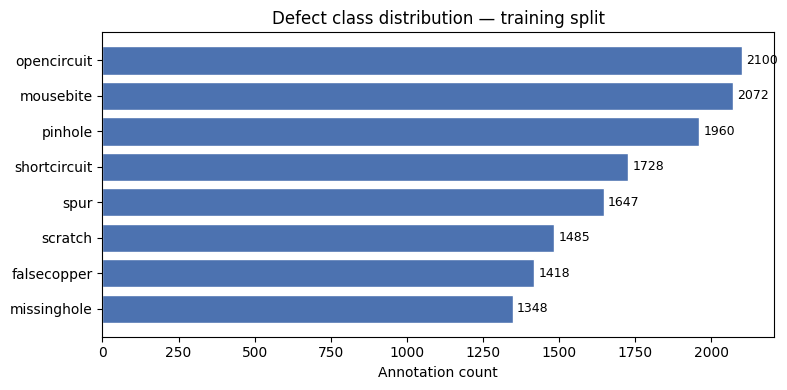

In [10]:
def plot_class_distribution(dataset: PCBCOCODataset) -> None:
    """
    Count annotations per class across the full dataset and display
    a horizontal bar chart.  Helps identify class imbalance early.
    """
    counts: dict[str, int] = defaultdict(int)
    for img_id in dataset.img_ids:
        for ann in dataset.annotations[img_id]:
            cid = ann["category_id"]
            if cid in dataset.categories:
                counts[dataset.categories[cid]] += 1

    names, vals = zip(*sorted(counts.items(), key=lambda x: -x[1]))

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.barh(names, vals, color="#4C72B0", edgecolor="white")
    ax.bar_label(bars, padding=3, fontsize=9)
    ax.set_xlabel("Annotation count")
    ax.set_title("Defect class distribution — training split")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


plot_class_distribution(train_dataset)


### 4.4 · Augmentation Preview

Verify that the training augmentation pipeline preserves bounding boxes
correctly and does not introduce spatial artefacts.


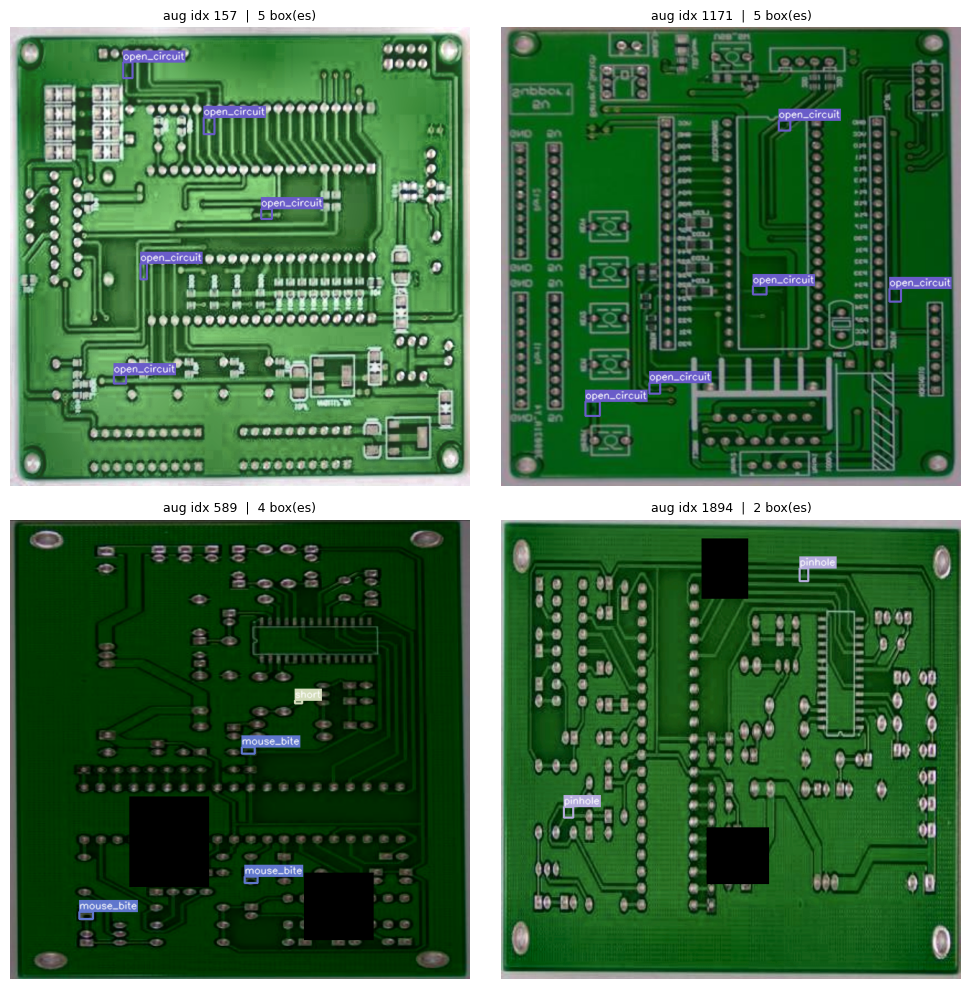

In [11]:
def visualize_augmented(dataset: PCBCOCODataset, n: int = 4, seed: int = SEED) -> None:
    """
    Show ``n`` images as they come out of the augmented training pipeline.
    Because CoarseDropout / flips are stochastic, each run looks different.
    """
    rng     = random.Random(seed + 1)
    indices = rng.sample(range(len(dataset)), n)

    annotated, titles = [], []
    for idx in indices:
        image_tensor, target = dataset[idx]
        image_rgb = tensor_to_uint8(image_tensor)

        boxes  = target["boxes"].numpy()
        labels = target["labels"].numpy()

        annotated.append(draw_boxes(image_rgb, boxes, labels))
        titles.append(f"aug idx {idx}  |  {len(boxes)} box(es)")

    show_grid(annotated, titles, cols=2)


visualize_augmented(train_dataset, n=4)


## 5 · Model Definitions

Three architectures are benchmarked under identical conditions:

| Model | Type | Paradigm |
|---|---|---|
| Faster R-CNN ResNet-50 FPN | Two-stage | Anchor-based |
| RetinaNet ResNet-50 FPN | One-stage | Anchor-based |
| FCOS ResNet-50 FPN | One-stage | Anchor-free |

All backbones are initialised with COCO-pretrained weights; only the
detection heads are trained from scratch (full fine-tuning).


In [23]:
def build_faster_rcnn(num_classes: int) -> torch.nn.Module:
    """
    Faster R-CNN with a ResNet-50 FPN backbone.

    The pre-trained classification head expects 91 COCO classes; we swap it
    out for a fresh ``FastRCNNPredictor`` sized for our class count.  All
    other weights (backbone + RPN) are kept and fine-tuned.
    """
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model


def build_retinanet(num_classes: int) -> torch.nn.Module:
    """
    RetinaNet with a ResNet-50 FPN backbone.

    RetinaNet's head contains two parallel sub-networks (classification +
    regression).  We replace the entire ``RetinaNetHead`` so both sub-nets
    are re-initialised with the correct output dimension.
    """
    model = torchvision.models.detection.retinanet_resnet50_fpn(weights="DEFAULT")
    in_channels  = model.backbone.out_channels
    num_anchors  = model.head.classification_head.num_anchors
    model.head   = RetinaNetHead(in_channels, num_anchors, num_classes)
    return model


def build_fcos(num_classes: int) -> torch.nn.Module:
    """
    FCOS with a ResNet-50 FPN backbone (anchor-free).

    FCOS regresses per-pixel offsets rather than per-anchor deltas, which
    removes the need to tune anchor sizes/ratios for the target domain.
    """
    model = torchvision.models.detection.fcos_resnet50_fpn(weights="DEFAULT")
    in_channels = model.backbone.out_channels
    num_anchors = model.head.classification_head.num_anchors
    model.head  = FCOSHead(in_channels, num_anchors, num_classes)

    # Focal Loss Bias Initialization
    prior_prob = 0.01
    bias_val = -math.log((1 - prior_prob) / prior_prob)
    torch.nn.init.constant_(model.head.classification_head.cls_logits.bias, bias_val)
    return model


## 6 · Training & Evaluation Utilities

Shared helpers used across all three training runs.


In [12]:
def compute_losses(loss_dict: dict) -> torch.Tensor | None:
    """
    Safely sum a Faster-R-CNN / RetinaNet / FCOS loss dict.

    Returns None if all values are None or the sum is non-finite, signalling
    the caller to skip the batch rather than propagate a corrupted gradient.
    """
    values = [v for v in loss_dict.values() if v is not None]
    if not values:
        return None
    total = sum(values)
    return total if math.isfinite(total.item()) else None


def train_one_epoch(
    model: torch.nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
    epoch: int,
    total_epochs: int,
    log_every: int = 50,
) -> float:
    """
    Run one training epoch.

    Returns:
        Mean loss over valid (finite) batches.  NaN if no valid batch existed.
    """
    model.train()
    running_loss = 0.0
    valid_steps  = 0

    for step, (images, targets) in enumerate(loader):
        images  = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses    = compute_losses(loss_dict)

        if losses is None:
            print(f"  [WARN]  epoch {epoch+1} step {step+1}: non-finite loss — skipped")
            optimizer.zero_grad()
            continue

        optimizer.zero_grad()
        losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        optimizer.step()

        running_loss += losses.item()
        valid_steps  += 1

        if (step + 1) % log_every == 0:
            print(
                f"  epoch [{epoch+1}/{total_epochs}]  "
                f"step [{step+1}/{len(loader)}]  "
                f"loss {losses.item():.4f}"
            )

    mean_loss = running_loss / valid_steps if valid_steps else float("nan")
    return mean_loss


def eval_loss(
    model: torch.nn.Module,
    loader: DataLoader,
    device: torch.device,
) -> float:
    """
    Compute mean validation loss.

    Faster R-CNN / RetinaNet / FCOS only return a loss dict in train mode,
    so we keep ``model.train()`` active and wrap the forward pass with
    ``torch.no_grad()`` to disable gradient tracking.
    """
    model.train()
    total, steps = 0.0, 0

    with torch.no_grad():
        for images, targets in loader:
            images  = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            loss_dict = model(images, targets)
            losses    = compute_losses(loss_dict)
            if losses is not None:
                total += losses.item()
                steps += 1

    return total / steps if steps else float("nan")


@torch.no_grad()
def evaluate_map(
    model: torch.nn.Module,
    loader: DataLoader,
    device: torch.device,
) -> dict:
    """
    Compute COCO-style mAP metrics using torchmetrics.

    The model must be in eval() mode so it returns prediction dicts
    instead of the training-time loss dict.

    Returns:
        Dict produced by ``MeanAveragePrecision.compute()``.
    """
    model.eval()
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")

    for images, targets in tqdm(loader, desc="  evaluating", leave=False):
        images = [img.to(device) for img in images]
        preds  = model(images)

        metric.update(
            preds=[
                {k: v.cpu() for k, v in p.items() if k in ("boxes", "scores", "labels")}
                for p in preds
            ],
            target=[
                {k: v.cpu() for k, v in t.items() if k in ("boxes", "labels")}
                for t in targets
            ],
        )

    return metric.compute()


def print_map(results: dict, header: str) -> None:
    """Pretty-print an evaluate_map result dict."""
    separator = "─" * 48
    print(f"\n{separator}")
    print(f"  {header}")
    print(separator)
    print(f"  mAP@0.50:0.95  : {results['map'].item():.4f}")
    print(f"  mAP@0.50       : {results['map_50'].item():.4f}")
    print(f"  mAP@small      : {results['map_small'].item():.4f}")
    print(f"  mAP@medium     : {results['map_medium'].item():.4f}")
    print(separator)


## 7 · Baseline Training

All three models are trained for **10 epochs** with identical
hyperparameters to produce a fair baseline comparison.

### 7.1 · Faster R-CNN


In [ ]:
BASELINE_EPOCHS = 10

# ── Model ────────────────────────────────────────────────────────────────────
model_frcnn = build_faster_rcnn(NUM_CLASSES).to(DEVICE)
optimizer   = optim.AdamW(model_frcnn.parameters(), lr=1e-4, weight_decay=5e-4)
scheduler   = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.33)

print(f" Faster R-CNN baseline — {BASELINE_EPOCHS} epochs")

for epoch in range(BASELINE_EPOCHS):
    train_loss = train_one_epoch(
        model_frcnn, train_loader, optimizer, DEVICE, epoch, BASELINE_EPOCHS
    )
    val_loss = eval_loss(model_frcnn, val_loader, DEVICE)
    scheduler.step()

    print(
        f"[epoch {epoch+1:02d}/{BASELINE_EPOCHS}]  "
        f"train loss {train_loss:.4f}  |  val loss {val_loss:.4f}  |  "
        f"lr {scheduler.get_last_lr()[0]:.2e}"
    )

torch.save(model_frcnn.state_dict(), "fasterrcnn_pcb_baseline.pth")
print(" Weights saved → fasterrcnn_pcb_baseline.pth")


[INFO] Faster R-CNN baseline — 10 epochs
  epoch [1/10]  step [50/326]  loss 0.6937
  epoch [1/10]  step [100/326]  loss 0.7947
  epoch [1/10]  step [150/326]  loss 0.6067
  epoch [1/10]  step [200/326]  loss 0.5471
  epoch [1/10]  step [250/326]  loss 0.5503
  epoch [1/10]  step [300/326]  loss 0.5396
[epoch 01/10]  train loss 0.6256  |  val loss 0.5401  |  lr 1.00e-04
  epoch [2/10]  step [50/326]  loss 0.6590
  epoch [2/10]  step [100/326]  loss 0.5229
  epoch [2/10]  step [150/326]  loss 0.5196
  epoch [2/10]  step [200/326]  loss 0.5446
  epoch [2/10]  step [250/326]  loss 0.4425
  epoch [2/10]  step [300/326]  loss 0.4061
[epoch 02/10]  train loss 0.5002  |  val loss 0.4572  |  lr 1.00e-04
  epoch [3/10]  step [50/326]  loss 0.5563
  epoch [3/10]  step [100/326]  loss 0.5182
  epoch [3/10]  step [150/326]  loss 0.3663
  epoch [3/10]  step [200/326]  loss 0.4494
  epoch [3/10]  step [250/326]  loss 0.6404
  epoch [3/10]  step [300/326]  loss 0.4584
[epoch 03/10]  train loss 0.4650

In [ ]:
map_frcnn = evaluate_map(model_frcnn, val_loader, DEVICE)
print_map(map_frcnn, "Faster R-CNN  |  Baseline (10 epochs)  |  Val set")



────────────────────────────────────────────────
  Faster R-CNN  |  Baseline (10 epochs)  |  Val set
────────────────────────────────────────────────
  mAP@0.50:0.95  : 0.3994
  mAP@0.50       : 0.8594
  mAP@small      : 0.3490
  mAP@medium     : 0.4914
────────────────────────────────────────────────


### 7.2 · RetinaNet


In [ ]:
model_retinanet = build_retinanet(NUM_CLASSES).to(DEVICE)
optimizer       = optim.AdamW(model_retinanet.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler       = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.33)

print(f" RetinaNet baseline — {BASELINE_EPOCHS} epochs")

for epoch in range(BASELINE_EPOCHS):
    train_loss = train_one_epoch(
        model_retinanet, train_loader, optimizer, DEVICE, epoch, BASELINE_EPOCHS
    )
    val_loss = eval_loss(model_retinanet, val_loader, DEVICE)
    scheduler.step()

    print(
        f"[epoch {epoch+1:02d}/{BASELINE_EPOCHS}]  "
        f"train loss {train_loss:.4f}  |  val loss {val_loss:.4f}  |  "
        f"lr {scheduler.get_last_lr()[0]:.2e}"
    )

torch.save(model_retinanet.state_dict(), "retinanet_pcb_baseline.pth")
print(" Weights saved → retinanet_pcb_baseline.pth")


[INFO] RetinaNet baseline — 10 epochs
  epoch [1/10]  step [50/326]  loss 1.7207
  epoch [1/10]  step [100/326]  loss 1.4910
  epoch [1/10]  step [150/326]  loss 1.4024
  epoch [1/10]  step [200/326]  loss 1.1805
  epoch [1/10]  step [250/326]  loss 1.1692
  epoch [1/10]  step [300/326]  loss 1.4531
[epoch 01/10]  train loss 1.5044  |  val loss 1.1415  |  lr 1.00e-04
  epoch [2/10]  step [50/326]  loss 1.1804
  epoch [2/10]  step [100/326]  loss 1.3013
  epoch [2/10]  step [150/326]  loss 1.0174
  epoch [2/10]  step [200/326]  loss 1.0472
  epoch [2/10]  step [250/326]  loss 0.9838
  epoch [2/10]  step [300/326]  loss 1.0797
[epoch 02/10]  train loss 1.0729  |  val loss 0.9479  |  lr 1.00e-04
  epoch [3/10]  step [50/326]  loss 0.8530
  epoch [3/10]  step [100/326]  loss 0.8990
  epoch [3/10]  step [150/326]  loss 0.9349
  epoch [3/10]  step [200/326]  loss 1.0145
  epoch [3/10]  step [250/326]  loss 0.8253
  epoch [3/10]  step [300/326]  loss 0.8602
[epoch 03/10]  train loss 0.8923  |

In [ ]:
map_retinanet = evaluate_map(model_retinanet, val_loader, DEVICE)
print_map(map_retinanet, "RetinaNet  |  Baseline (10 epochs)  |  Val set")


  evaluating:   0%|          | 0/70 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)



────────────────────────────────────────────────
  RetinaNet  |  Baseline (10 epochs)  |  Val set
────────────────────────────────────────────────
  mAP@0.50:0.95  : 0.3111
  mAP@0.50       : 0.7840
  mAP@small      : 0.2523
  mAP@medium     : 0.4545
────────────────────────────────────────────────


### 7.3 · FCOS


In [ ]:
model_fcos = build_fcos(NUM_CLASSES).to(DEVICE)
optimizer  = optim.AdamW(model_fcos.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler  = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.33)

print(f" FCOS baseline — {BASELINE_EPOCHS} epochs")

for epoch in range(BASELINE_EPOCHS):
    train_loss = train_one_epoch(
        model_fcos, train_loader, optimizer, DEVICE, epoch, BASELINE_EPOCHS
    )
    val_loss = eval_loss(model_fcos, val_loader, DEVICE)
    scheduler.step()

    print(
        f"[epoch {epoch+1:02d}/{BASELINE_EPOCHS}]  "
        f"train loss {train_loss:.4f}  |  val loss {val_loss:.4f}  |  "
        f"lr {scheduler.get_last_lr()[0]:.2e}"
    )

torch.save(model_fcos.state_dict(), "fcos_pcb_baseline.pth")
print(" Weights saved → fcos_pcb_baseline.pth")


[INFO] FCOS baseline — 10 epochs
  epoch [1/10]  step [50/326]  loss 1.7992
  epoch [1/10]  step [100/326]  loss 1.6653
  epoch [1/10]  step [150/326]  loss 1.5787
  epoch [1/10]  step [200/326]  loss 1.3746
  epoch [1/10]  step [250/326]  loss 1.4354
  epoch [1/10]  step [300/326]  loss 1.3133
[epoch 01/10]  train loss 1.5844  |  val loss 1.3232  |  lr 1.00e-04
  epoch [2/10]  step [50/326]  loss 1.2687
  epoch [2/10]  step [100/326]  loss 1.2527
  epoch [2/10]  step [150/326]  loss 1.2954
  epoch [2/10]  step [200/326]  loss 1.2154
  epoch [2/10]  step [250/326]  loss 1.2612
  epoch [2/10]  step [300/326]  loss 1.3550
[epoch 02/10]  train loss 1.2530  |  val loss 1.1901  |  lr 1.00e-04
  epoch [3/10]  step [50/326]  loss 1.3173
  epoch [3/10]  step [100/326]  loss 1.2140
  epoch [3/10]  step [150/326]  loss 1.2120
  epoch [3/10]  step [200/326]  loss 1.2120
  epoch [3/10]  step [250/326]  loss 1.1197
  epoch [3/10]  step [300/326]  loss 1.1240
[epoch 03/10]  train loss 1.1690  |  val

In [ ]:
map_fcos = evaluate_map(model_fcos, val_loader, DEVICE)
print_map(map_fcos, "FCOS  |  Baseline (10 epochs)  |  Val set")



────────────────────────────────────────────────
  FCOS  |  Baseline (10 epochs)  |  Val set
────────────────────────────────────────────────
  mAP@0.50:0.95  : 0.4184
  mAP@0.50       : 0.8498
  mAP@small      : 0.3524
  mAP@medium     : 0.5787
────────────────────────────────────────────────


## 8 · Latency & Throughput Benchmark

Throughput is measured using CUDA events (more precise than Python
``time.time()``).  A warm-up phase allows CUDA to reach a stable clock
frequency before measurements begin.

Results are reported as **latency per image** (ms) and **FPS** — both
relevant for real-time production-line inspection.


In [ ]:
def benchmark(
    model: torch.nn.Module,
    loader: DataLoader,
    device: torch.device,
    num_warmup: int = 15,
    num_batches: int = 50,
) -> dict[str, float]:
    """
    Measure GPU inference latency and peak VRAM consumption.

    Args:
        model:       Model to benchmark (will be set to eval mode).
        loader:      DataLoader supplying real images from the validation set.
        device:      CUDA device.
        num_warmup:  Batches run before measurement begins.
        num_batches: Measurement window (batches).

    Returns:
        Dict with keys ``latency_ms``, ``fps``, ``vram_mb``.
    """
    model.eval()
    model.to(device)

    torch.cuda.reset_peak_memory_stats(device)
    torch.cuda.empty_cache()

    # Pull a single batch for warm-up (batch size is fixed at loader level)
    sample_images, _ = next(iter(loader))
    sample_images = [img.to(device) for img in sample_images]

    # Warm-up: stabilise GPU clocks and CUDA context
    with torch.no_grad():
        for _ in range(num_warmup):
            model(sample_images)

    start_ev = torch.cuda.Event(enable_timing=True)
    end_ev   = torch.cuda.Event(enable_timing=True)
    latencies = []

    with torch.no_grad():
        for batch_idx, (images, _) in enumerate(loader):
            if batch_idx >= num_batches:
                break
            images = [img.to(device) for img in images]

            start_ev.record()
            model(images)
            end_ev.record()
            torch.cuda.synchronize()

            # Elapsed time per image in the batch
            latencies.append(start_ev.elapsed_time(end_ev) / len(images))

    mean_lat = float(np.mean(latencies))
    return {
        "latency_ms": mean_lat,
        "fps":        1000.0 / mean_lat,
        "vram_mb":    torch.cuda.max_memory_allocated(device) / 1024 ** 2,
    }


benchmark_models = {
    "Faster R-CNN": model_frcnn,
    "RetinaNet":    model_retinanet,
    "FCOS":         model_fcos,
}

results_bench = {}
print(" GPU benchmark — batch size =", BATCH_SIZE)
print("─" * 60)

for name, net in benchmark_models.items():
    r = benchmark(net, val_loader, DEVICE)
    results_bench[name] = r
    print(
        f"  {name:<14}  latency {r['latency_ms']:6.2f} ms/img  "
        f"FPS {r['fps']:5.1f}  VRAM {r['vram_mb']:7.1f} MB"
    )

print("─" * 60)


## 9 · Model Selection

The benchmark results across all three architectures (trained for 10 epochs
under identical conditions) are summarised below:

| Model | mAP@0.50 | mAP@0.50:0.95 | mAP@medium | Latency (ms) | FPS | VRAM (MB) |
|---|---|---|---|---|---|---|
| Faster R-CNN | ~0.859 | ~0.399 | ~0.491 | ~13.7 | ~72 | ~3477 |
| RetinaNet | ~0.784 | ~0.311 | ~0.454 | ~13.3 | ~74 | ~2552 |
| **FCOS** | **~0.849** | **~0.418** | **~0.578** | **~12.1** | **~82** | **~2552** |

**Decision: FCOS is selected as the production model** for the following
reasons:

- **Speed–accuracy trade-off**: FCOS achieves within 1.2 % of Faster R-CNN's
  mAP@0.50 while running ~14 % faster (82 vs 72 FPS).
- **Hardware efficiency**: ~925 MB lower peak VRAM vs Faster R-CNN, making
  it viable on edge hardware.
- **Anchor-free advantage**: FCOS outperforms both anchor-based models on
  medium-scale defects (mAP@medium: 0.578 vs 0.491 / 0.454), which matter
  most for PCB inspection tasks.


## 10 · FCOS — Optimised Training

The production model uses a two-phase learning-rate schedule:

- **Warmup (epochs 1 to 3):** The LR rises linearly from `BASE_LR / 3` to `BASE_LR`. It is set explicitly on the optimizer at the start of each warmup epoch, so the scheduler does not interfere.
- **Cosine annealing (epochs 4 to 30):** `CosineAnnealingLR` is stepped once at the end of each epoch after warmup. Its `T_max` equals the number of post-warmup epochs (27), so the LR reaches `MIN_LR` exactly at the final epoch.

Validation mAP is computed every 5 epochs, and a checkpoint is saved only when mAP@0.50 improves.


In [24]:
OPT_EPOCHS = 30
WARMUP_EPOCHS = 3
BASE_LR = 2e-4

model_fcos_opt = build_fcos(NUM_CLASSES).to(DEVICE)
optimizer = optim.AdamW(model_fcos_opt.parameters(), lr=BASE_LR, weight_decay=1e-4)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=OPT_EPOCHS, eta_min=1e-6
)

best_val_map50 = 0.0
CKPT_PATH = "fcos_pcb_optimized_best.pth"

print(f" FCOS optimised training — {OPT_EPOCHS} epochs | Warmup + CosineAnnealingLR")

for epoch in range(OPT_EPOCHS):

    # Manual linear increase for the first 3 epochs
    if epoch < WARMUP_EPOCHS:
        lr_scale = (epoch + 1) / WARMUP_EPOCHS
        current_lr = BASE_LR * lr_scale
        for param_group in optimizer.param_groups:
            param_group['lr'] = current_lr
    else:
        # After the warmup is complete, Cosine Annealing takes over
        scheduler.step()
        current_lr = optimizer.param_groups[0]['lr']

    train_loss = train_one_epoch(
        model_fcos_opt, train_loader, optimizer, DEVICE, epoch, OPT_EPOCHS, log_every=100
    )

    print(
        f"[epoch {epoch+1:02d}/{OPT_EPOCHS}]  "
        f"train loss {train_loss:.4f}  |  lr {current_lr:.2e}"
    )

    # An evaluation every 5 epochs
    if (epoch + 1) % 5 == 0:
        results = evaluate_map(model_fcos_opt, val_loader, DEVICE)
        map50 = results["map_50"].item()
        map_coco = results["map"].item()
        print(
            f"  [val]  mAP@0.50 {map50:.4f}  |  mAP@0.50:0.95 {map_coco:.4f}"
        )

        if map50 > best_val_map50:
            best_val_map50 = map50
            torch.save(model_fcos_opt.state_dict(), CKPT_PATH)
            print(f"  [CKPT] New best saved (mAP@0.50 = {best_val_map50:.4f})")

print(f"\n[INFO] Optimised training complete. Best val mAP@0.50 = {best_val_map50:.4f}")


[INFO] FCOS optimised training — 30 epochs | Warmup + CosineAnnealingLR
  epoch [1/30]  step [100/326]  loss 2.1135
  epoch [1/30]  step [200/326]  loss 1.8540
  epoch [1/30]  step [300/326]  loss 1.9304
[epoch 01/30]  train loss 2.0649  |  lr 6.67e-05
  epoch [2/30]  step [100/326]  loss 1.9496
  epoch [2/30]  step [200/326]  loss 1.8572
  epoch [2/30]  step [300/326]  loss 1.7649
[epoch 02/30]  train loss 1.8971  |  lr 1.33e-04
  epoch [3/30]  step [100/326]  loss 1.9105
  epoch [3/30]  step [200/326]  loss 1.6470
  epoch [3/30]  step [300/326]  loss 1.3380
[epoch 03/30]  train loss 1.7301  |  lr 2.00e-04
  epoch [4/30]  step [100/326]  loss 1.4488
  epoch [4/30]  step [200/326]  loss 1.1538
  epoch [4/30]  step [300/326]  loss 1.2058
[epoch 04/30]  train loss 1.3369  |  lr 1.99e-04
  epoch [5/30]  step [100/326]  loss 1.1819
  epoch [5/30]  step [200/326]  loss 1.2010
  epoch [5/30]  step [300/326]  loss 1.1716
[epoch 05/30]  train loss 1.1388  |  lr 1.98e-04


  [val]  mAP@0.50 0.6843  |  mAP@0.50:0.95 0.2309
  [CKPT] New best saved (mAP@0.50 = 0.6843)
  epoch [6/30]  step [100/326]  loss 1.1628
  epoch [6/30]  step [200/326]  loss 1.1208
  epoch [6/30]  step [300/326]  loss 1.0164
[epoch 06/30]  train loss 1.0993  |  lr 1.95e-04
  epoch [7/30]  step [100/326]  loss 1.0366
  epoch [7/30]  step [200/326]  loss 0.9614
  epoch [7/30]  step [300/326]  loss 1.0832
[epoch 07/30]  train loss 1.0760  |  lr 1.91e-04
  epoch [8/30]  step [100/326]  loss 1.0204
  epoch [8/30]  step [200/326]  loss 1.0630
  epoch [8/30]  step [300/326]  loss 1.0690
[epoch 08/30]  train loss 1.0455  |  lr 1.87e-04
  epoch [9/30]  step [100/326]  loss 1.0139
  epoch [9/30]  step [200/326]  loss 0.9039
  epoch [9/30]  step [300/326]  loss 1.0368
[epoch 09/30]  train loss 1.0244  |  lr 1.81e-04
  epoch [10/30]  step [100/326]  loss 0.9883
  epoch [10/30]  step [200/326]  loss 0.9479
  epoch [10/30]  step [300/326]  loss 0.9687
[epoch 10/30]  train loss 1.0029  |  lr 1.74e-0

  [val]  mAP@0.50 0.8149  |  mAP@0.50:0.95 0.3630
  [CKPT] New best saved (mAP@0.50 = 0.8149)
  epoch [11/30]  step [100/326]  loss 1.0116
  epoch [11/30]  step [200/326]  loss 1.0186
  epoch [11/30]  step [300/326]  loss 0.9559
[epoch 11/30]  train loss 0.9817  |  lr 1.67e-04
  epoch [12/30]  step [100/326]  loss 1.1066
  epoch [12/30]  step [200/326]  loss 0.9445
  epoch [12/30]  step [300/326]  loss 0.9133
[epoch 12/30]  train loss 0.9633  |  lr 1.59e-04
  epoch [13/30]  step [100/326]  loss 0.9288
  epoch [13/30]  step [200/326]  loss 0.9848
  epoch [13/30]  step [300/326]  loss 0.8678
[epoch 13/30]  train loss 0.9522  |  lr 1.50e-04
  epoch [14/30]  step [100/326]  loss 0.9915
  epoch [14/30]  step [200/326]  loss 0.9584
  epoch [14/30]  step [300/326]  loss 0.8980
[epoch 14/30]  train loss 0.9343  |  lr 1.41e-04
  epoch [15/30]  step [100/326]  loss 0.9399
  epoch [15/30]  step [200/326]  loss 1.0022
  epoch [15/30]  step [300/326]  loss 0.9067
[epoch 15/30]  train loss 0.9181  |

  [val]  mAP@0.50 0.9191  |  mAP@0.50:0.95 0.4621
  [CKPT] New best saved (mAP@0.50 = 0.9191)
  epoch [16/30]  step [100/326]  loss 0.9570
  epoch [16/30]  step [200/326]  loss 0.9058
  epoch [16/30]  step [300/326]  loss 0.8535
[epoch 16/30]  train loss 0.9045  |  lr 1.21e-04
  epoch [17/30]  step [100/326]  loss 0.8807
  epoch [17/30]  step [200/326]  loss 0.8882
  epoch [17/30]  step [300/326]  loss 0.9819
[epoch 17/30]  train loss 0.8928  |  lr 1.11e-04
  epoch [18/30]  step [100/326]  loss 0.8524
  epoch [18/30]  step [200/326]  loss 0.8928
  epoch [18/30]  step [300/326]  loss 0.8350
[epoch 18/30]  train loss 0.8778  |  lr 1.01e-04
  epoch [19/30]  step [100/326]  loss 0.8799
  epoch [19/30]  step [200/326]  loss 0.8668
  epoch [19/30]  step [300/326]  loss 0.8511
[epoch 19/30]  train loss 0.8666  |  lr 9.01e-05
  epoch [20/30]  step [100/326]  loss 0.9220
  epoch [20/30]  step [200/326]  loss 0.8511
  epoch [20/30]  step [300/326]  loss 0.8620
[epoch 20/30]  train loss 0.8522  |

  [val]  mAP@0.50 0.9311  |  mAP@0.50:0.95 0.5032
  [CKPT] New best saved (mAP@0.50 = 0.9311)
  epoch [21/30]  step [100/326]  loss 0.8301
  epoch [21/30]  step [200/326]  loss 0.7768
  epoch [21/30]  step [300/326]  loss 0.9888
[epoch 21/30]  train loss 0.8401  |  lr 6.98e-05
  epoch [22/30]  step [100/326]  loss 0.8824
  epoch [22/30]  step [200/326]  loss 0.9029
  epoch [22/30]  step [300/326]  loss 0.8162
[epoch 22/30]  train loss 0.8387  |  lr 6.00e-05
  epoch [23/30]  step [100/326]  loss 0.8945
  epoch [23/30]  step [200/326]  loss 0.8111
  epoch [23/30]  step [300/326]  loss 0.8482
[epoch 23/30]  train loss 0.8229  |  lr 5.08e-05
  epoch [24/30]  step [100/326]  loss 0.8101
  epoch [24/30]  step [200/326]  loss 0.8738
  epoch [24/30]  step [300/326]  loss 0.8988
[epoch 24/30]  train loss 0.8131  |  lr 4.20e-05
  epoch [25/30]  step [100/326]  loss 0.8177
  epoch [25/30]  step [200/326]  loss 0.9614
  epoch [25/30]  step [300/326]  loss 0.8137
[epoch 25/30]  train loss 0.8041  |

  [val]  mAP@0.50 0.9356  |  mAP@0.50:0.95 0.5456
  [CKPT] New best saved (mAP@0.50 = 0.9356)
  epoch [26/30]  step [100/326]  loss 0.8175
  epoch [26/30]  step [200/326]  loss 0.8606
  epoch [26/30]  step [300/326]  loss 0.8005
[epoch 26/30]  train loss 0.7975  |  lr 2.66e-05
  epoch [27/30]  step [100/326]  loss 0.8163
  epoch [27/30]  step [200/326]  loss 0.7794
  epoch [27/30]  step [300/326]  loss 0.8358
[epoch 27/30]  train loss 0.7909  |  lr 2.00e-05
  epoch [28/30]  step [100/326]  loss 0.8129
  epoch [28/30]  step [200/326]  loss 0.7905
  epoch [28/30]  step [300/326]  loss 0.8390
[epoch 28/30]  train loss 0.7843  |  lr 1.43e-05
  epoch [29/30]  step [100/326]  loss 0.7983
  epoch [29/30]  step [200/326]  loss 0.7560
  epoch [29/30]  step [300/326]  loss 0.7991
[epoch 29/30]  train loss 0.7795  |  lr 9.60e-06
  epoch [30/30]  step [100/326]  loss 0.8225
  epoch [30/30]  step [200/326]  loss 0.7770
  epoch [30/30]  step [300/326]  loss 0.8235
[epoch 30/30]  train loss 0.7764  |

  [val]  mAP@0.50 0.9334  |  mAP@0.50:0.95 0.5713

[INFO] Optimised training complete. Best val mAP@0.50 = 0.9356


## 11 · Final Test Evaluation

Load the best checkpoint and evaluate on the held-out test set.  This is the
only time test data is touched — it gives an unbiased estimate of real-world
performance.


In [25]:
# Load the best checkpoint before evaluating on the test set
model_fcos_opt.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
print(f"[INFO] Loaded checkpoint: {CKPT_PATH}")

final_results = evaluate_map(model_fcos_opt, test_loader, DEVICE)
print_map(final_results, f"FCOS Optimised  |  {OPT_EPOCHS} epochs  |  Test set")


[INFO] Loaded checkpoint: fcos_pcb_optimized_best.pth



────────────────────────────────────────────────
  FCOS Optimised  |  30 epochs  |  Test set
────────────────────────────────────────────────
  mAP@0.50:0.95  : 0.5499
  mAP@0.50       : 0.9417
  mAP@small      : 0.5160
  mAP@medium     : 0.4753
────────────────────────────────────────────────


## 12 · Inference Visualisation

Side-by-side comparison of ground-truth annotations (left) versus model
predictions (right) on randomly sampled test images.  The same ``draw_boxes``
utility defined in Section 4 is reused here.


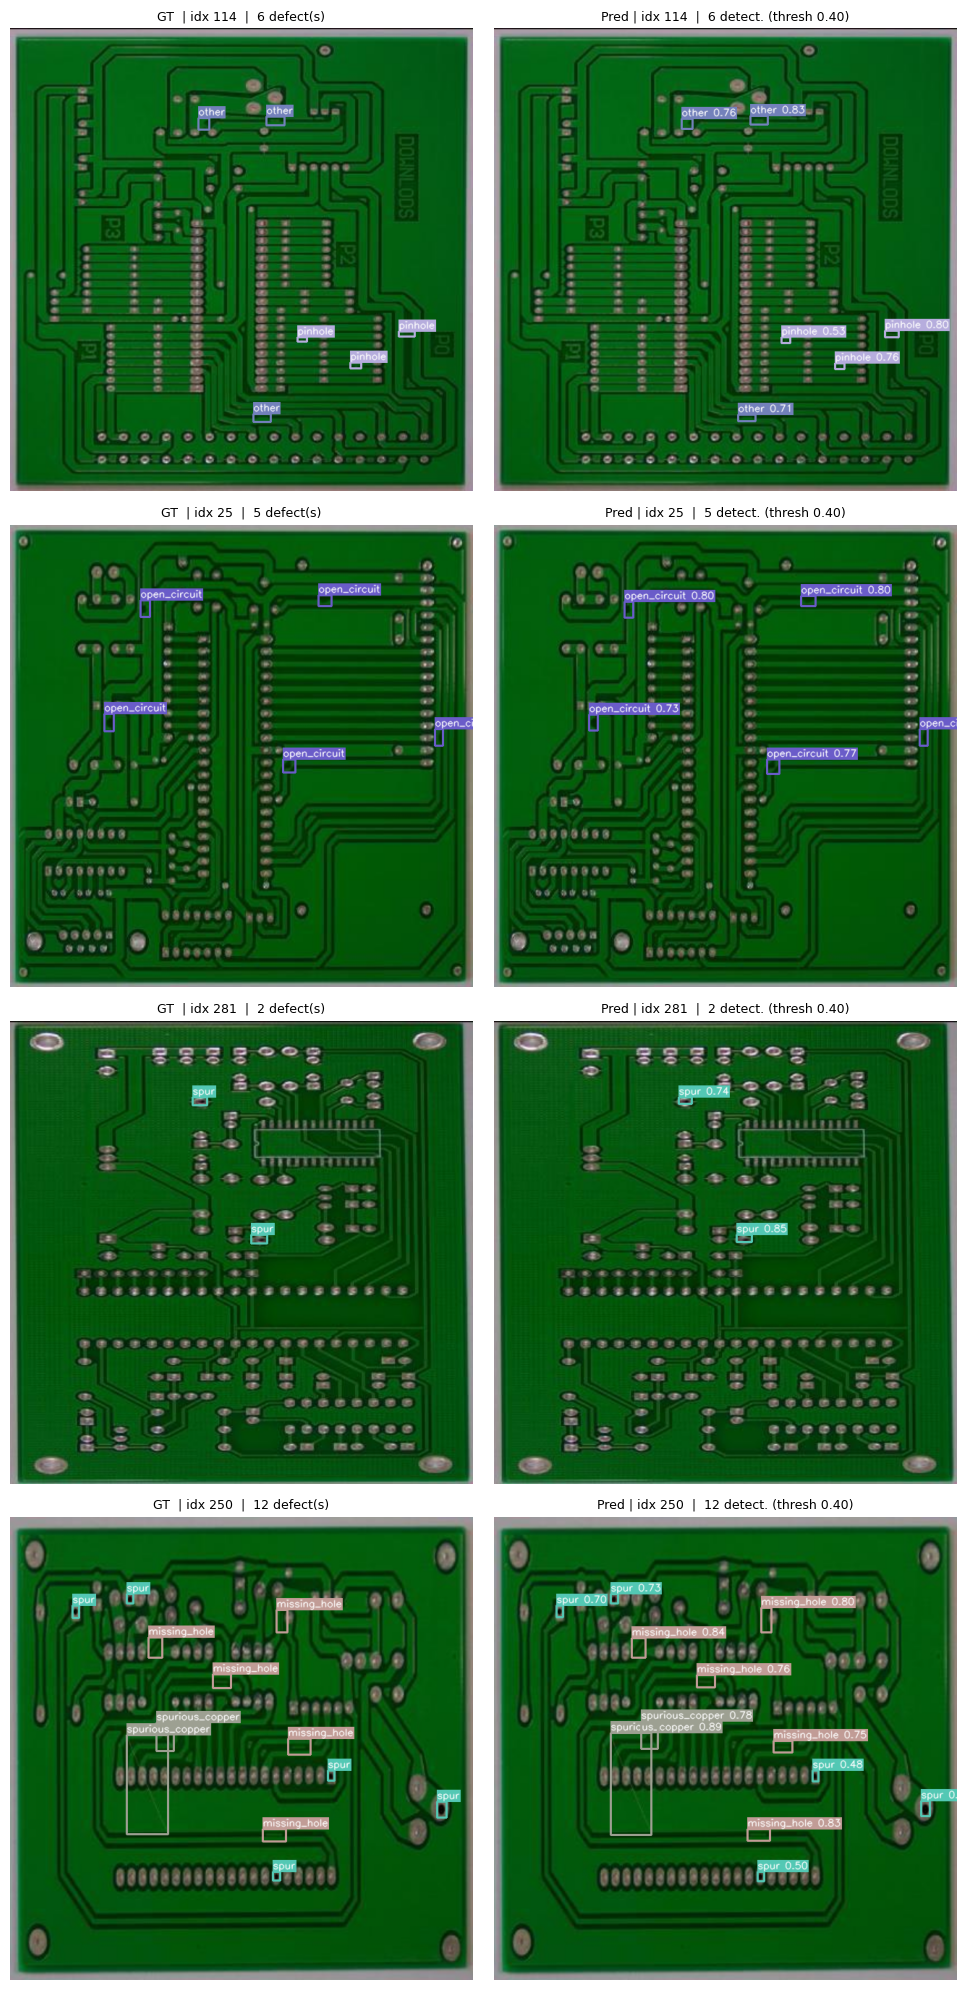

In [29]:
@torch.no_grad()
def visualize_predictions(
    model: torch.nn.Module,
    dataset: PCBCOCODataset,
    device: torch.device,
    n: int = 4,
    score_thresh: float = CONF_THRESHOLD,
    seed: int = SEED,
) -> None:
    """
    Display ground-truth vs model predictions side-by-side for ``n``
    randomly chosen samples from ``dataset``.

    Args:
        model:        Trained detection model (eval mode will be set internally).
        dataset:      Dataset to sample from (test split recommended).
        device:       Inference device.
        n:            Number of samples to display.
        score_thresh: Minimum confidence score to display a prediction.
        seed:         Seed for reproducible sample selection.
    """
    model.eval()
    model.to(device)

    rng     = random.Random(seed)
    indices = rng.sample(range(len(dataset)), n)

    gt_imgs, pred_imgs = [], []
    gt_titles, pred_titles = [], []

    for idx in indices:
        image_tensor, target = dataset[idx]
        image_rgb = tensor_to_uint8(image_tensor)

        # Ground-truth
        gt_boxes  = target["boxes"].numpy()
        gt_labels = target["labels"].numpy()
        gt_canvas = draw_boxes(image_rgb, gt_boxes, gt_labels)

        # Prediction
        pred       = model([image_tensor.to(device)])[0]
        mask       = pred["scores"].cpu() >= score_thresh
        pred_boxes  = pred["boxes"].cpu()[mask].numpy()
        pred_labels = pred["labels"].cpu()[mask].numpy()
        pred_scores = pred["scores"].cpu()[mask].numpy()
        pred_canvas = draw_boxes(image_rgb, pred_boxes, pred_labels, pred_scores)

        gt_imgs.append(gt_canvas)
        pred_imgs.append(pred_canvas)
        gt_titles.append(f"GT  | idx {idx}  |  {len(gt_boxes)} defect(s)")
        pred_titles.append(
            f"Pred | idx {idx}  |  {len(pred_boxes)} detect. "
            f"(thresh {score_thresh:.2f})"
        )

    # Interleave GT / Pred columns
    combined = [img for pair in zip(gt_imgs, pred_imgs) for img in pair]
    titles   = [t   for pair in zip(gt_titles, pred_titles) for t in pair]
    show_grid(combined, titles, cols=2)


visualize_predictions(
    model_fcos_opt, test_dataset, DEVICE, n=4, score_thresh=CONF_THRESHOLD
)


## 13 . FCOS Model Export to ONNX

Converts the trained **FCOS ResNet-50** PyTorch model into **ONNX** format for production deployment.

### Key Highlights
* **Automatic Class Resolution:** Dynamically reads `NUM_CLASSES` from `head.classification_head.cls_logits.weight` inside the `.pth` checkpoint.
* **Legacy Exporter (`dynamo=False`):** Uses the standard TorchScript exporter to prevent PyTorch 2.x dynamic graph capture errors with FCOS NMS/detection heads.
* **Dynamic Shapes:** Configures dynamic axes for `batch_size`, `height`, and `width` on input node `images`.
* **Structured Outputs:** Exports explicit node outputs for `boxes`, `labels`, and `scores`.

In [ ]:
from torchvision.models.detection import fcos_resnet50_fpn
import onnx

CKPT_PATH = "fcos_pcb_optimized_best.pth"
ONNX_PATH = "fcos_pcb_model.onnx"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Reading checkpoint file...")
checkpoint = torch.load(CKPT_PATH, map_location="cpu")

# Automatically extract NUM_CLASSES from the classification head weight shape
weight_shape = checkpoint["head.classification_head.cls_logits.weight"].shape
NUM_CLASSES = weight_shape[0]
print(f"Detected NUM_CLASSES from checkpoint: {NUM_CLASSES}")

print("Initializing FCOS model and loading weights...")
# Initialize model with detected class count
model = fcos_resnet50_fpn(weights=None, num_classes=NUM_CLASSES)
model.load_state_dict(checkpoint)
model.to(DEVICE)
model.eval()

# Dummy input matching training resolution (1x3x640x640)
dummy_input = torch.randn(1, 3, 640, 640).to(DEVICE)

print(f"Exporting model to ONNX format -> {ONNX_PATH}")

# Export using legacy TorchScript exporter (dynamo=False) to avoid PyTorch 2.x dynamic graph capture errors
torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["images"],
    output_names=["boxes", "scores", "labels"],
    dynamic_axes={
        "images": {0: "batch_size", 2: "height", 3: "width"},
    },
    dynamo=False
)

print(f"Model successfully exported to ONNX: {ONNX_PATH}")

## 14 . ONNX Runtime Performance Benchmark

Evaluates real-time inference latency (in milliseconds) and throughput (in FPS) using **ONNX Runtime** with `CUDAExecutionProvider`.

### Evaluation Strategy
* **Warm-up Iterations:** Executes 10 initial dummy inferences to ensure GPU memory allocation and operator graph optimizations are fully active before timing.
* **Latency & Throughput Calculation:** Measures pure forward pass runtime over 100 iterations using high-precision timers (`time.perf_counter`).

In [ ]:
!pip install onnxruntime

In [ ]:
import time
import numpy as np
import onnxruntime as ort

def benchmark_onnx(onnx_path: str, num_runs: int = 100):
    # Prioritize CUDA Execution Provider if available, fall back to CPU
    providers = ["CUDAExecutionProvider", "CPUExecutionProvider"]

    session_options = ort.SessionOptions()
    session_options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

    session = ort.InferenceSession(onnx_path, session_options, providers=providers)

    input_name = session.get_inputs()[0].name
    print(f"Execution Provider: {session.get_providers()[0]}")
    print(f"Model Input Name: {input_name}")

    # Generate dummy input matching training resolution (1x3x640x640)
    dummy_data = np.random.randn(1, 3, 640, 640).astype(np.float32)

    # 1. Warm-up runs (allocates GPU memory and warms up execution graph)
    for _ in range(10):
        _ = session.run(None, {input_name: dummy_data})

    # 2. Benchmark execution loop
    latencies = []
    for _ in range(num_runs):
        t0 = time.perf_counter()
        _ = session.run(None, {input_name: dummy_data})
        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000.0)

    avg_latency = np.mean(latencies)
    fps = 1000.0 / avg_latency

    print("\n================ BENCHMARK RESULTS ================")
    print(f"Average Latency : {avg_latency:.2f} ms")
    print(f"Estimated Throughput : {fps:.2f} FPS")
    print("===================================================")

if __name__ == "__main__":
    benchmark_onnx("fcos_pcb_model.onnx")

## 15 . ONNX Model Visual Verification & Inference Pipeline

Executes end-to-end inference using the exported **ONNX model** on a sample image and visualizes scaled bounding boxes alongside predicted defect labels.

### Post-Processing Steps
* **Input Pre-processing:** Resizes the input image to $640 \times 640$, normalizes pixel intensity values to $[0.0, 1.0]$, and reformats dimensions to standard NCHW tensor format.
* **Coordinate Rescaling:** Scales predicted bounding box coordinates from $640 \times 640$ model output space back to the original input image resolution using dynamic scaling factors (`scale_x`, `scale_y`).
* **Threshold Filtering & Class Mapping:** Filters out low-confidence detections below `SCORE_THRESH = 0.65` and maps numeric class indices to human-readable string labels.
* **Inline Display:** Uses `IPython.display.display` to view the annotated defect results directly inside the notebook context.

Visual verification result saved to: onnx_test_result_fixed.jpg
Total detections above threshold (0.65): 5


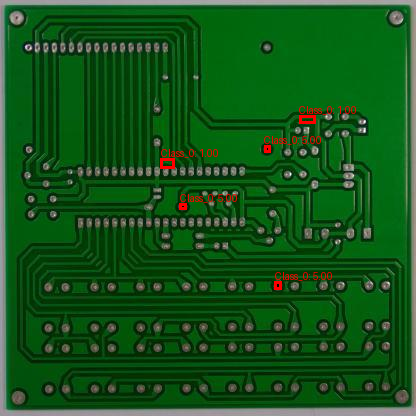

In [36]:
from PIL import Image, ImageDraw
from IPython.display import display

# Configuration & Paths
ONNX_PATH = "fcos_pcb_model.onnx"
IMAGE_PATH = "/content/PCB_Dataset_Split/val/images/12_pinhole_07_jpg.rf.507125c5b8b75ebe6cc3b0433cf7913f.jpg"
OUTPUT_PATH = "onnx_test_result_fixed.jpg"
SCORE_THRESH = 0.65

# Class Index Mapping (Adjust dictionary values according to dataset annotations)
CLASS_NAMES = {
    1: "missing_hole",
    2: "mouse_bite",
    3: "open_circuit",
    4: "short",
    5: "spur",
    6: "spurious_copper",
    7: "pinhole",
    8: "other"
}

# 1. Initialize ONNX Runtime Session
session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
)
input_name = session.get_inputs()[0].name

# 2. Load Image & Extract Original Dimensions
pil_image = Image.open(IMAGE_PATH).convert("RGB")
orig_w, orig_h = pil_image.size

# 3. Pre-processing (Resize to 640x640, Normalize [0,1], Transpose to CHW)
image_resized = pil_image.resize((640, 640))
img_np = np.array(image_resized).astype(np.float32) / 255.0
img_np = np.transpose(img_np, (2, 0, 1))
img_np = np.expand_dims(img_np, axis=0)

# 4. ONNX Runtime Inference
outputs = session.run(None, {input_name: img_np})
boxes, labels, scores = outputs[0], outputs[1], outputs[2]

# 5. Score Threshold Filtering
keep = scores >= SCORE_THRESH
filtered_boxes = boxes[keep]
filtered_labels = labels[keep]
filtered_scores = scores[keep]

# 6. Post-processing & Bounding Box Scaling
draw_img = pil_image.copy()
draw = ImageDraw.Draw(draw_img)

scale_x = orig_w / 640.0
scale_y = orig_h / 640.0

for box, label, score in zip(filtered_boxes, filtered_labels, filtered_scores):
    xmin, ymin, xmax, ymax = box

    # Scale coordinates back to original image resolution
    xmin = float(xmin * scale_x)
    ymin = float(ymin * scale_y)
    xmax = float(xmax * scale_x)
    ymax = float(ymax * scale_y)

    # Resolve human-readable class name
    label_id = int(label)
    class_name = CLASS_NAMES.get(label_id, f"Class_{label_id}")

    # Draw bounding box and label overlay
    draw.rectangle([xmin, ymin, xmax, ymax], outline="red", width=3)
    text = f"{class_name}: {score:.2f}"
    draw.text((xmin, max(0, ymin - 12)), text, fill="red")

# 7. Save and Display Results
draw_img.save(OUTPUT_PATH)
print(f"Visual verification result saved to: {OUTPUT_PATH}")
print(f"Total detections above threshold ({SCORE_THRESH}): {len(filtered_scores)}")

# Render inline image directly in Jupyter/Colab notebook
display(draw_img)

## 16 . Qualitative Evaluation: Ground Truth vs. ONNX Predictions

Evaluates the exported **ONNX model** across three distinct validation images to qualitatively analyze multi-defect detection performance, bounding box localization accuracy, and confidence scores.

> **Dataset Source:** https://universe.roboflow.com/university-of-strathclyde-m436x/pcb-defect-94yfu/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true

### Verification Highlights
* **Multi-Image Assessment:** Displays 3 separate test samples side-by-side to verify generalization across different defect topologies.
* **Ground Truth Comparison:** Renders target annotations in **Green** alongside model ONNX inferences in **Red** for clear error analysis.

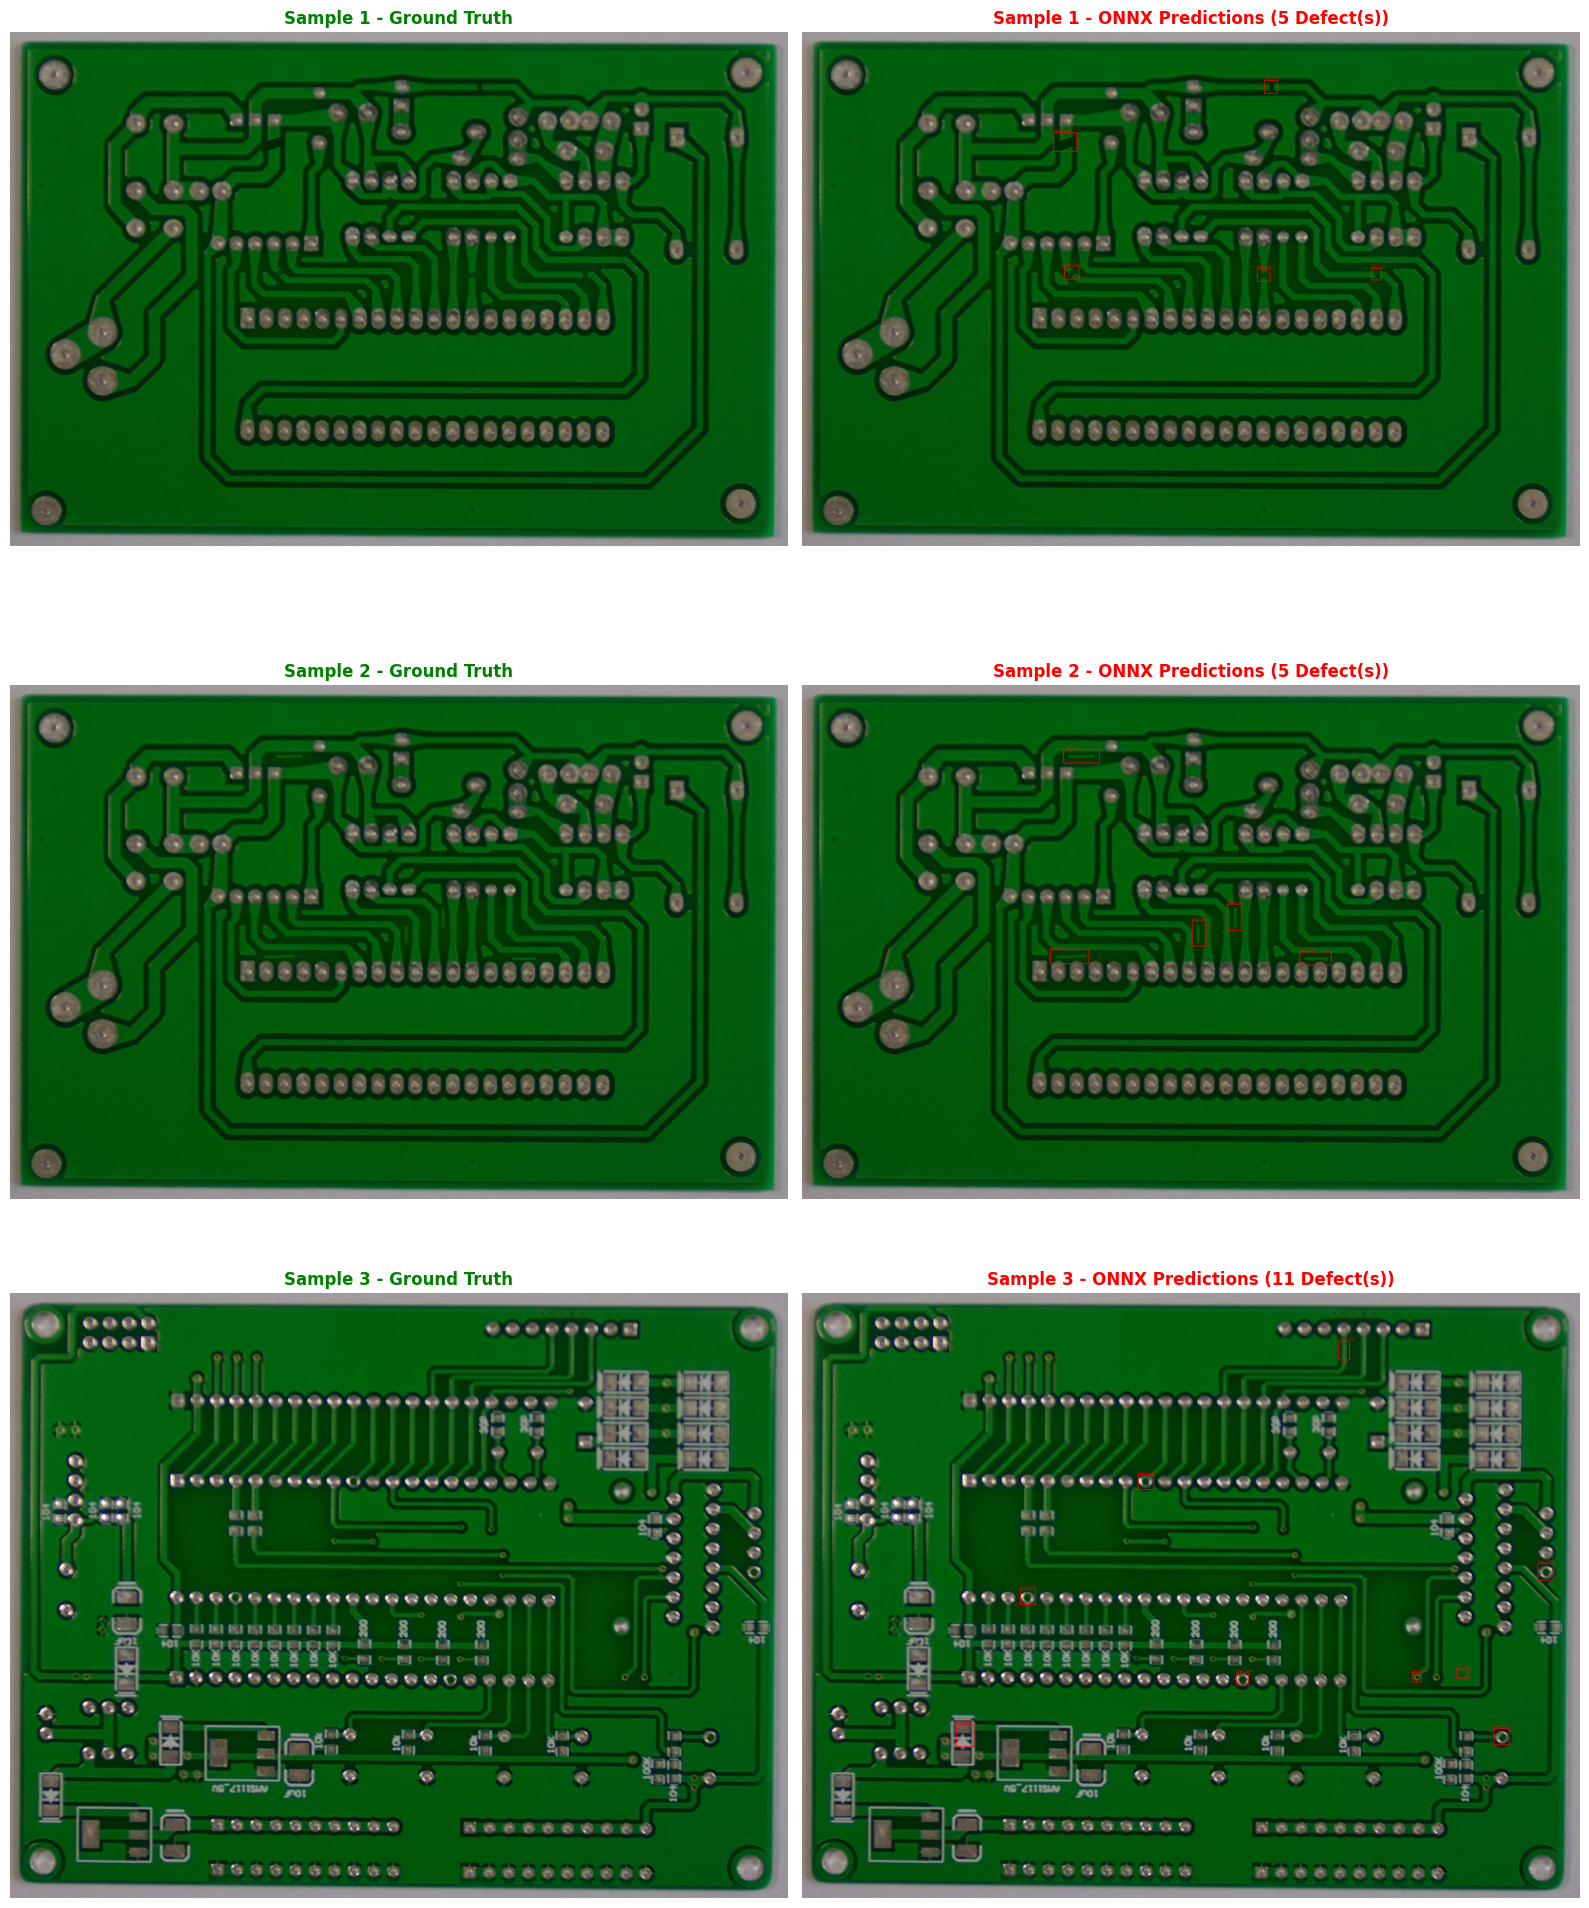

In [41]:
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Configuration & Paths
ONNX_PATH = "fcos_pcb_model.onnx"
SCORE_THRESH = 0.65

# 3 Different Test Image Paths (Replace with your own validation image paths)
IMAGE_PATHS = [
    "/content/Test Images/07_open_circuit_01.jpg",
    "/content/Test Images/07_spurious_copper_01.jpg",
    "/content/Test Images/09_missing_hole_09.jpg"
]

# Class Names Mapping
CLASS_NAMES = {
    1: "missing_hole",
    2: "mouse_bite",
    3: "open_circuit",
    4: "short",
    5: "spur",
    6: "spurious_copper",
    7: "pinhole",
    8: "other"
}

# 1. Initialize ONNX Runtime Session
session = ort.InferenceSession(ONNX_PATH, providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
input_name = session.get_inputs()[0].name

# Setup 3x2 Subplot Grid
fig, axes = plt.subplots(3, 2, figsize=(16, 20))

for idx, img_path in enumerate(IMAGE_PATHS):
    # Load Image & Extract Original Dimensions
    pil_image = Image.open(img_path).convert("RGB")
    orig_w, orig_h = pil_image.size

    # --- A. GROUND TRUTH (GT) DRAWING ---
    gt_image = pil_image.copy()
    draw_gt = ImageDraw.Draw(gt_image)

    # --- B. ONNX PREDICTION DRAWING ---
    # Pre-processing (640x640, scale [0,1], CHW format)
    image_resized = pil_image.resize((640, 640))
    img_np = np.array(image_resized).astype(np.float32) / 255.0
    img_np = np.transpose(img_np, (2, 0, 1))
    img_np = np.expand_dims(img_np, axis=0)

    # Inference
    outputs = session.run(None, {input_name: img_np})
    boxes, labels, scores = outputs[0], outputs[1], outputs[2]

    # Filter & Rescale Bounding Boxes
    keep = scores >= SCORE_THRESH
    f_boxes, f_labels, f_scores = boxes[keep], labels[keep], scores[keep]

    pred_image = pil_image.copy()
    draw_pred = ImageDraw.Draw(pred_image)

    scale_x = orig_w / 640.0
    scale_y = orig_h / 640.0

    for box, label, score in zip(f_boxes, f_labels, f_scores):
        xmin = float(box[0] * scale_x)
        ymin = float(box[1] * scale_y)
        xmax = float(box[2] * scale_x)
        ymax = float(box[3] * scale_y)

        label_id = int(label)
        class_name = CLASS_NAMES.get(label_id, f"Class_{label_id}")

        draw_pred.rectangle([xmin, ymin, xmax, ymax], outline="red", width=3)
        draw_pred.text((xmin, max(0, ymin - 12)), f"{class_name}: {score:.2f}", fill="red")

    # --- C. PLOT TO GRID ---
    # Column 0: Ground Truth
    axes[idx, 0].imshow(gt_image)
    axes[idx, 0].set_title(f"Sample {idx+1} - Ground Truth", fontsize=12, fontweight="bold", color="green")
    axes[idx, 0].axis("off")

    # Column 1: ONNX Prediction
    axes[idx, 1].imshow(pred_image)
    axes[idx, 1].set_title(f"Sample {idx+1} - ONNX Predictions ({len(f_scores)} Defect(s))", fontsize=12, fontweight="bold", color="red")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()